Random matrix theory

Raeding material: before addressing this exercise, it is recommended that i study the chapter on Shrinkage. "26.a.62

Code reference: become familiar with script "s_marchenko_pastur",
which illustrates the spectrum estimation via random matrix theory.

Consider a multivariate i.i.d process of dimension i_bar = 300

In [6]:
from matplotlib.pyplot import legend
from numpy import cov, linspace, pi, sqrt
from numpy import allclose
from numpy.linalg import eigvals
from numpy.random import randn
from scipy.stats import expon, norm as normal
from skrmt.ensemble.spectral_law import MarchenkoPasturDistribution as MP
from seaborn import lineplot, histplot

Task 1:

Suppose the process is normally distributed as follows

Et = (Ei...E100) ~ N(0300x1, ||300).

Generate a set of t_bar = 1,500 observations {Et}t_bar, t=1 , and verify the approximation of sample spectrum
via the Marchenko-Pastur distribution with q=i_bar/t_bar

Run a controlled experiment in 4 steps:
- "Simulate" 1500 days of returns for 300 stocks, that are all independent with variance 1.
The true covariance is identity matrix ||300
- "Estimate" the sample covariance from the data, a 300x300 matrix.
- "Compute its eigenvalues", which gives 300 numbers.
- "Plot" a histogram of those eigenvalues and lay the Marchenko-Pastur (MP) curve on top.
(Check that they match)

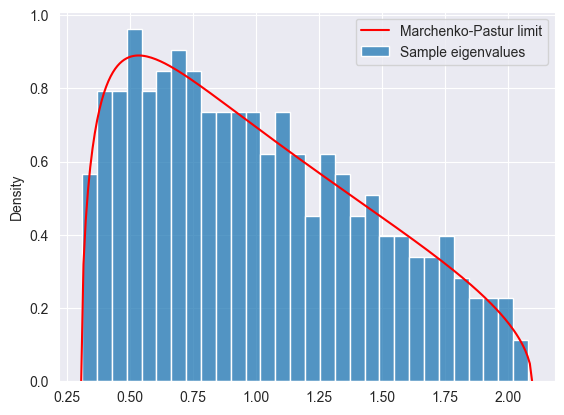

In [7]:
############### inputs ###############
# dimension of process
i_bar = 300
# number of observation
t_bar = 1500
######################################

# the simulated normal scenarios
# randn() draws stand normals, with mean 0 and variance 1, into a 1500x300 array.
# a table of 1500 daily returns for 300 stocks,
eps_1 = randn(t_bar, i_bar)
# the sample covariance matrix for those normal scenarios
sigma2_1 = cov(eps_1.T)
# eigenvalues (lambda) of normal scenarios, returns the 300 eigenvalues.
lam_1 = eigvals(sigma2_1)

# Marchenko-Pasture curve
# the ratio of variables to observations (300/1500=0.2)
q = i_bar / t_bar
# lower bound edges of noise
lam_minus = (1 - sqrt(q))**2
# upper bound edges of noise
lam_plus = (1 + sqrt(q))**2

# define Marchenko-Pastur distribution
# here because ~= 0.2 then first part of this lambda (q > 1) does not switch
# the second part is the MP curve
f_mp = lambda l: ((1 - 1/q) * normal.pdf(l, 0, 10**(-2)) * (q > 1)
                  + 1/(2*pi*l*q)*sqrt((l - lam_minus)*(lam_plus - l)*(lam_minus < l < lam_plus)))

# grid of 200 evenly spaced eigenvalue positions, lambda to lambda (x-xis values)
x_mp = linspace(lam_minus, lam_plus, 200)
# Marchenko-Pastur approximation for the normal and the exponential
# looping through the eigenvalue positions and calculating the heights of each (y-axis values)
y_mp = [f_mp(x) for x in x_mp]

############################### plot ###############################
# normal vs its Marchenko-Pastur approximation
lineplot(x=x_mp, y=y_mp, color='r', label='Marchenko-Pastur limit')
histplot(x=lam_1, stat='density', bins=30, label='Sample eigenvalues')
legend();

In [9]:
# CROSS-CHECK MP formula vs the scikit-rmt library version

# beta=1 means real valued data
mp = MP(ratio=q, beta=1)
# library's curve (which skips the 2 exact edge points)
y_lib = mp.pdf(x_mp[1:-1])
# True means the curves match
print(allclose(y_lib, y_mp[1:-1]))

True


Task 2:

(Non-normal data)  - testing does the Marchenko-Pastur law depend on normal data/

Suppose the process is made by random variables Ei,t that are cross-sectionally independent and identically distributed
as a shifted exponential

Ei,t ~ Exponential(1) - 1.

for any i=1,...,300.

Generate a set of t_bar=1,500 observations {Et}t_bar,t=1' and verify that the approximation in Task 1 still holds.

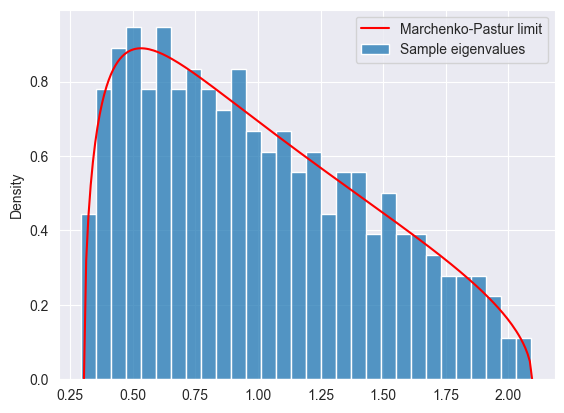

In [10]:
# exponential scenarios, but draws from the exponential dist (1500x300 table)
# - 1 shifts every number down by 1, so the mean becomes 0
eps_2 = expon.rvs(size=(t_bar, i_bar)) - 1
# covariance of exponential scenarios
sigma2_2 = cov(eps_2.T)
# eigenvalues of exponential scenarios
lam_2 = eigvals(sigma2_2)

# covraiance and eigenvalue lines are same as Task 1, only data changes.
# grid
x_mp_2 = x_mp
# Marchenko-Pastur approximation for the normal and the exponential
y_mp_2 = y_mp

################################# plot #################################
# exponential vs its Marchenko-Pastur approximation
lineplot(x=x_mp_2, y=y_mp_2, color='r', label='Marchenko-Pastur limit')
histplot(x=lam_2, stat='density', bins=30, label='Sample eigenvalues')
legend();


Task 3:

(variance 4 instead of 1)

Suppose the process is normally distributed as follows

Et ~N(0 300x1, 4 x || 300).

Generate a set of t_bar=1,500 observations {Et}t_bar,t=1' and verify that the
approximation in Task 1 does not hold more.

In [ ]:
# rescaled normal scenarios
eps_3 =
# covariance of rescaled normal scenarios
sigma2_3 =
# eigenvalues of rescaled normal scenarios
lam_3 =

# grid
x_mp_3 =
# Marchenko-Pastur approximation for the normal and the exponential
y_mp_3 =

################################# plot #################################
# exponential vs its Marchenko-Pastur approximation
lineplot(x=x_mp_3, y=y_mp_3, color='r', label='Marchenko-Pastur limit')
histplot(x=lam_3, stat='density', label='Sample eigenvalues')

Task 4:

Comment the results obtained in Task 1, Task 2, Task 3, (max 80 words)

Hint; Check the processes which verify the constraints.

Answer: